# Physiology brightness screening — Bocas 2026

Screen the physiology recordings for brightness changes, keeping each Panama observation night independent. A night is labeled by the evening on which it begins: all recordings from noon on one date through noon the next date share the same `night_date`. This keeps an approximately 17:30–08:00 recording together across midnight.

Videos are downloaded one at a time, scanned over the full frame, and deleted. Per-video CSVs are stored in separate night folders so processing can resume safely. Filename timestamps are interpreted as UTC by `scripts/brightnessOverTime.py` and converted to Panama time before grouping.

For vessel-focused stationary-pulse discovery and review clips, use [physiology_pulse_discovery_Bocas2026.ipynb](physiology_pulse_discovery_Bocas2026.ipynb).

In [22]:
DATASET = {
    "key": "physiology_bocas2026",
    "label": "Physiology — Bocas 2026",
    "box_url": "https://ucsb.box.com/s/dwav1fq9nqys8l1uve1fqdhoez33y4z2",
}

TIMEZONE = "America/Panama"
NIGHT_BOUNDARY_HOUR = 12  # noon; 17:30 through 08:00 remains one night
NIGHTS_TO_PROCESS = None  # e.g. ["2026-08-23"]; None processes every discovered night
BATCH_START_WITHIN_NIGHT = 0
BATCH_SIZE_WITHIN_NIGHT = 10000
FRAME_STEP = 5
MAX_WIDTH = 320  # temporal templates are much cheaper at screening resolution
CALIBRATION_SECONDS = None  # None uses the entire ~2-minute chunk
CALIBRATION_SAMPLE_HZ = 5
MIN_BLINK_AMPLITUDE = 8
MIN_BLINK_DUTY = 0.05  # protects rare flashes from entering the nuisance model
MIN_LIGHT_CORE_PIXELS = 2
MAX_LIGHT_SOURCES = 30
PREDICTED_SATURATION_THRESHOLD = 250
RIDGE_PENALTY = 0.1
RESIDUAL_NOISE_FLOOR = 3
REUSE_MODEL_WITHIN_NIGHT = True
REFERENCE_VIDEO_BY_NIGHT = {
    "2026-08-28": "data/selected_videos/physiology/sbs_20260828_235910.mkv",
}
SHOW_BLINK_DIAGNOSTICS = True
TOP_FRACTION = 0.001
PERCENTILE = 99.9
BRIGHT_THRESHOLD = 200
FORCE_REPROCESS = False
MEAN_Y_AXIS_MAX = 0.05
BRIGHT_Y_AXIS_MAX = 50

In [23]:
import importlib.util
import json
import re
import sys
import tempfile
import time
import urllib.error
import urllib.parse
import urllib.request
from pathlib import Path
from zoneinfo import ZoneInfo

import cv2
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "scripts" / "brightnessOverTime.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
SCRIPT_PATH = PROJECT_ROOT / "scripts" / "brightnessOverTime.py"
RESULTS_ROOT = PROJECT_ROOT / "data" / "processed" / "physiology_brightness_temporal_only_parts_Bocas2026"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

spec = importlib.util.spec_from_file_location("brightness_over_time", SCRIPT_PATH)
brightness = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = brightness
spec.loader.exec_module(brightness)
local_zone = ZoneInfo(TIMEZONE)

In [24]:
BOX_DATA_RE = re.compile(r"Box\.(?:postStreamData|prefetchedData)\s*=\s*(\{.*?\});", re.DOTALL)
VIDEO_EXTENSIONS = {"avi", "m4v", "mkv", "mov", "mp4", "mpg", "mpeg"}

def _read_url(url, attempts=4):
    headers = {"User-Agent": "Mozilla/5.0", "Accept": "text/html,application/xhtml+xml"}
    for attempt in range(1, attempts + 1):
        try:
            request = urllib.request.Request(url, headers=headers)
            with urllib.request.urlopen(request, timeout=60) as response:
                return response.read().decode("utf-8")
        except (urllib.error.HTTPError, urllib.error.URLError, TimeoutError) as error:
            if attempt == attempts:
                raise RuntimeError(f"Box request failed after {attempts} attempts: {url}") from error
            wait = 2 ** (attempt - 1)
            print(f"Box request failed ({error}); retrying in {wait} seconds...")
            time.sleep(wait)

def night_label(time_panama):
    return (time_panama - pd.Timedelta(hours=NIGHT_BOUNDARY_HOUR)).date().isoformat()

def list_box_videos(shared_url):
    rows, page = [], 1
    while True:
        html = _read_url(f"{shared_url}{'&' if '?' in shared_url else '?'}page={page}")
        candidates = [json.loads(match.group(1)) for match in BOX_DATA_RE.finditer(html)]
        post_data = next((data for data in candidates
                          if "/app-api/enduserapp/shared-folder" in data), None)
        if post_data is None:
            raise RuntimeError("Could not find Box folder metadata. Check that the link is public.")
        folder = post_data["/app-api/enduserapp/shared-folder"]
        rows.extend({"id": int(item["id"]), "name": item["name"],
                     "size_bytes": int(item["itemSize"])}
                    for item in folder["items"]
                    if item.get("type") == "file"
                    and item.get("extension", "").lower() in VIDEO_EXTENSIONS)
        if page >= int(folder["pageCount"]):
            break
        page += 1
    if not rows:
        raise RuntimeError("No video files were found in the shared Box folder.")
    shared_name = post_data["/app-api/enduserapp/shared-item"]["sharedName"]
    table = pd.DataFrame(rows).drop_duplicates("id")
    table["size_GB"] = table["size_bytes"] / 1e9
    table["start_utc"] = table["name"].map(brightness.parse_utc_start)
    bad_names = table.loc[table["start_utc"].isna(), "name"].tolist()
    if bad_names:
        examples = "\n".join(f"  - {name}" for name in bad_names[:10])
        raise ValueError("Could not read a UTC timestamp from these filenames:\n" + examples)
    table["start_utc"] = pd.to_datetime(table["start_utc"], utc=True)
    table["start_panama"] = table["start_utc"].dt.tz_convert(TIMEZONE)
    table["night_date"] = table["start_panama"].map(night_label)
    return table.sort_values(["start_utc", "name"]).reset_index(drop=True), shared_name

def download_box_file(shared_name, file_id, destination, block_size=8 * 1024 * 1024):
    query = urllib.parse.urlencode({"rm": "box_download_shared_file",
                                    "shared_name": shared_name, "file_id": f"f_{file_id}"})
    request = urllib.request.Request(f"https://ucsb.app.box.com/index.php?{query}",
                                     headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request, timeout=120) as response, destination.open("wb") as output:
        total, downloaded = int(response.headers.get("Content-Length", 0)), 0
        while block := response.read(block_size):
            output.write(block)
            downloaded += len(block)
            if total:
                print(f"\rDownloaded {downloaded / total:6.1%}", end="")
    print()

def _screening_gray(frame):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    return brightness.resize_for_screening(gray, MAX_WIDTH)

def fit_blink_model(path):
    """Learn the recurring illumination cycle and fixed light locations."""
    capture = cv2.VideoCapture(str(path))
    if not capture.isOpened():
        raise RuntimeError(f"OpenCV could not open {path.name}")
    fps = float(capture.get(cv2.CAP_PROP_FPS))
    if not np.isfinite(fps) or fps <= 0:
        capture.release()
        raise RuntimeError(f"No usable frame rate in {path.name}")
    calibration_step = max(1, int(round(fps / CALIBRATION_SAMPLE_HZ)))
    stop_frame = (int(round(CALIBRATION_SECONDS * fps))
                  if CALIBRATION_SECONDS is not None else float("inf"))
    frames, frame_number = [], 0
    try:
        while frame_number < stop_frame:
            ok, frame = capture.read()
            if not ok:
                break
            if frame_number % calibration_step == 0:
                frames.append(_screening_gray(frame))
            frame_number += 1
    finally:
        capture.release()
    if len(frames) < 20:
        raise RuntimeError(f"Only {len(frames)} calibration frames were available in {path.name}")

    stack = np.stack(frames)
    flat = stack.reshape(len(stack), -1).astype(np.float32)
    baseline = np.median(stack, axis=0).astype(np.float32)
    high = np.percentile(stack, 99, axis=0)
    amplitude = high - baseline
    active = stack > (baseline + MIN_BLINK_AMPLITUDE)
    duty = active.mean(axis=0)
    light_core = (amplitude >= MIN_BLINK_AMPLITUDE) & (duty >= MIN_BLINK_DUTY)

    component_count, labels, stats, _ = cv2.connectedComponentsWithStats(
        light_core.astype(np.uint8), connectivity=8
    )
    components = []
    for label in range(1, component_count):
        area = int(stats[label, cv2.CC_STAT_AREA])
        if area >= MIN_LIGHT_CORE_PIXELS:
            components.append((area, labels == label))
    components.sort(key=lambda item: item[0], reverse=True)
    components = components[:MAX_LIGHT_SOURCES]
    if not components:
        raise RuntimeError("No recurrent fixed lights were detected; lower MIN_BLINK_AMPLITUDE.")

    source_pixels = [np.flatnonzero(mask.ravel()) for _, mask in components]
    source_traces = np.column_stack([flat[:, pixels].mean(axis=1) for pixels in source_pixels])
    source_mean = source_traces.mean(axis=0)
    source_scale = source_traces.std(axis=0)
    source_scale[source_scale < 1] = 1
    standardized = (source_traces - source_mean) / source_scale
    design = np.column_stack([np.ones(len(stack)), standardized])
    penalty = np.eye(design.shape[1], dtype=np.float32) * RIDGE_PENALTY
    penalty[0, 0] = 0
    coefficients = np.linalg.solve(design.T @ design + penalty, design.T @ flat)

    source_core_map = np.logical_or.reduce([mask for _, mask in components])
    fitted = design @ coefficients
    rmse = float(np.sqrt(np.mean((flat - fitted) ** 2)))
    predicted_saturated_fraction = float((fitted >= PREDICTED_SATURATION_THRESHOLD).mean())
    return dict(fps=fps, calibration_step=calibration_step, source_core_map=source_core_map,
                source_pixels=source_pixels, source_mean=source_mean, source_scale=source_scale,
                coefficients=coefficients, source_traces=source_traces,
                sample_hz=fps / calibration_step, rmse=rmse,
                predicted_saturated_fraction=predicted_saturated_fraction)

def show_blink_diagnostics(model, video_name):
    times = np.arange(len(model["source_traces"])) / model["sample_hz"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
    for index in range(min(8, model["source_traces"].shape[1])):
        trace = model["source_traces"][:, index]
        axes[0].plot(times, trace - np.median(trace), lw=0.7, label=f"light {index + 1}")
    axes[0].set(xlabel="Calibration time (s)", ylabel="Brightness above median",
                title=f"Independent fixed-light traces ({model['source_traces'].shape[1]} found)")
    axes[0].legend(fontsize=7, ncol=2)
    axes[1].imshow(model["source_core_map"], cmap="gray", interpolation="nearest")
    axes[1].set(title="Light-tracking cores (diagnostic only; not persistently masked)")
    axes[1].axis("off")
    fig.suptitle(video_name + f"; calibration RMSE = {model['rmse']:.2f}")
    plt.show()

def scan_bioluminescence_with_progress(path, start_utc, model):
    capture = cv2.VideoCapture(str(path))
    if not capture.isOpened():
        raise RuntimeError(f"OpenCV could not open {path.name}")
    fps = float(capture.get(cv2.CAP_PROP_FPS))
    total_frames = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    rows, frame_number = [], 0
    try:
        while True:
            ok, frame = capture.read()
            if not ok:
                break
            if frame_number % FRAME_STEP == 0:
                gray = _screening_gray(frame).astype(np.float32)
                flat_gray = gray.ravel()
                source_values = np.asarray([flat_gray[pixels].mean()
                                            for pixels in model["source_pixels"]])
                standardized = (source_values - model["source_mean"]) / model["source_scale"]
                design_row = np.r_[1.0, standardized]
                predicted = (design_row @ model["coefficients"]).reshape(gray.shape)
                residual = gray - predicted - RESIDUAL_NOISE_FLOOR
                residual = np.clip(residual, 0, 255).astype(np.uint8)
                # Do not persistently mask the vessels. Only exclude pixels for frames
                # in which fiber illumination itself is predicted to saturate the sensor.
                residual[predicted >= PREDICTED_SATURATION_THRESHOLD] = 0
                mean, top_mean, pct, maximum, bright_fraction = brightness.brightness_metrics(
                    residual, TOP_FRACTION, PERCENTILE, BRIGHT_THRESHOLD
                )
                seconds = frame_number / fps
                time_utc = start_utc + pd.Timedelta(seconds=seconds)
                rows.append(brightness.Measurement(
                    path.name, frame_number, seconds, time_utc.to_pydatetime(),
                    time_utc.tz_convert(TIMEZONE).to_pydatetime(), mean, top_mean, pct,
                    maximum, bright_fraction,
                ))
            frame_number += 1
            if frame_number % 5000 == 0 or frame_number == total_frames:
                print(f"\rAnalyzed {frame_number:,}/{total_frames:,} frames", end="")
    finally:
        capture.release()
    print()
    return rows

## List recordings and separate observation nights

Run this cell before downloading anything. Confirm that the Panama timestamps and `night_date` assignments look right. Set `NIGHTS_TO_PROCESS` above if you want to run only selected nights.

In [26]:
videos, shared_name = list_box_videos(DATASET["box_url"])
available_nights = videos["night_date"].drop_duplicates().tolist()
selected_nights = available_nights if NIGHTS_TO_PROCESS is None else NIGHTS_TO_PROCESS
unknown_nights = sorted(set(selected_nights) - set(available_nights))
if unknown_nights:
    raise ValueError(f"Requested night(s) not found: {unknown_nights}; available: {available_nights}")

night_runs = {}
for night_date in selected_nights:
    night_videos = videos.loc[videos["night_date"] == night_date].copy()
    selected = night_videos.iloc[
        BATCH_START_WITHIN_NIGHT:BATCH_START_WITHIN_NIGHT + BATCH_SIZE_WITHIN_NIGHT
    ].copy()
    results_dir = RESULTS_ROOT / night_date
    results_dir.mkdir(parents=True, exist_ok=True)
    selected["result_exists"] = selected["name"].map(
        lambda name: (results_dir / f"{Path(name).stem}_brightness.csv").exists()
    )
    night_runs[night_date] = dict(videos=night_videos, selected=selected, results_dir=results_dir)

summary = videos.groupby("night_date").agg(
    videos=("id", "size"),
    first_start_panama=("start_panama", "min"),
    last_start_panama=("start_panama", "max"),
    total_GB=("size_GB", "sum"),
).reset_index()
print(f"Found {len(videos)} videos across {len(available_nights)} night(s).")
display(summary.style.format({"total_GB": "{:.3f}"}))
display(videos[["night_date", "name", "size_GB", "start_utc", "start_panama"]]
        .style.format({"size_GB": "{:.3f}"}))

Found 1795 videos across 5 night(s).


,night_date,videos,first_start_panama,last_start_panama,total_GB
0,2026-08-28,376,2026-08-28 18:19:10-05:00,2026-08-29 06:49:21-05:00,2.555
1,2026-08-29,375,2026-08-29 18:16:44-05:00,2026-08-30 06:44:54-05:00,3.682
2,2026-08-30,339,2026-08-30 18:27:28-05:00,2026-08-31 05:43:38-05:00,28.831
3,2026-08-31,351,2026-08-31 18:26:52-05:00,2026-09-01 06:07:01-05:00,3.140
4,2026-09-01,354,2026-09-01 18:21:19-05:00,2026-09-02 06:07:29-05:00,3.549


,night_date,name,size_GB,start_utc,start_panama
0,2026-08-28,sbs_20260828_231910.mkv,0.011,2026-08-28 23:19:10+00:00,2026-08-28 18:19:10-05:00
1,2026-08-28,sbs_20260828_232110.mkv,0.005,2026-08-28 23:21:10+00:00,2026-08-28 18:21:10-05:00
2,2026-08-28,sbs_20260828_232310.mkv,0.005,2026-08-28 23:23:10+00:00,2026-08-28 18:23:10-05:00
3,2026-08-28,sbs_20260828_232510.mkv,0.005,2026-08-28 23:25:10+00:00,2026-08-28 18:25:10-05:00
4,2026-08-28,sbs_20260828_232710.mkv,0.005,2026-08-28 23:27:10+00:00,2026-08-28 18:27:10-05:00
5,2026-08-28,sbs_20260828_232910.mkv,0.005,2026-08-28 23:29:10+00:00,2026-08-28 18:29:10-05:00
6,2026-08-28,sbs_20260828_233110.mkv,0.005,2026-08-28 23:31:10+00:00,2026-08-28 18:31:10-05:00
7,2026-08-28,sbs_20260828_233310.mkv,0.005,2026-08-28 23:33:10+00:00,2026-08-28 18:33:10-05:00
8,2026-08-28,sbs_20260828_233510.mkv,0.005,2026-08-28 23:35:10+00:00,2026-08-28 18:35:10-05:00
9,2026-08-28,sbs_20260828_233710.mkv,0.005,2026-08-28 23:37:10+00:00,2026-08-28 18:37:10-05:00


## Fit the blink model and process each night independently

The calibration pass finds recurrent fixed lights as separate spatial components. Their small core regions are used only to track the lights' independent intensity traces. A ridge-regression illumination model then learns each light's contribution to every pixel. The analysis pass subtracts only temporally predicted fiber illumination and measures the remaining positive light. There is no persistent spatial mask, so pixels beside a fiber remain eligible for courtship-signal detection whenever the fiber is off. Only pixels predicted to be sensor-saturated in the current frame are excluded because their underlying signal is unrecoverable. No shared blink period is assumed. Because camera geometry is stable across the short chunks, one model is reused within each night. The locally downloaded 18:59 reference clip is used for August 28; other nights use their first processed chunk. Set `REUSE_MODEL_WITHIN_NIGHT = False` if geometry changes.

Inspect the separate source traces, model RMSE, and light-tracking core map for at least the first video from every night. The core map is diagnostic and is not a persistent exclusion mask. Existing CSVs are skipped unless `FORCE_REPROCESS` is `True`.

In [28]:
for night_date, run in night_runs.items():
    selected = run["selected"]
    print(f"\n=== Night of {night_date} ({len(selected)} selected videos) ===")
    shared_model = None
    reference = REFERENCE_VIDEO_BY_NIGHT.get(night_date)
    if REUSE_MODEL_WITHIN_NIGHT and reference:
        reference_path = PROJECT_ROOT / reference
        if reference_path.exists():
            print(f"Fitting the night's light model from {reference_path.name}")
            shared_model = fit_blink_model(reference_path)
            print(f"Detected light sources: {len(shared_model['source_pixels'])}; "
                  f"calibration RMSE: {shared_model['rmse']:.2f}; "
                  f"dynamically saturated: {shared_model['predicted_saturated_fraction']:.3%}")
            if SHOW_BLINK_DIAGNOSTICS:
                show_blink_diagnostics(shared_model, reference_path.name)
        else:
            print(f"Reference not found: {reference_path}; using the first downloaded chunk.")
    for video_number, item in enumerate(selected.itertuples(index=False), start=1):
        result_path = run["results_dir"] / f"{Path(item.name).stem}_brightness.csv"
        if result_path.exists() and not FORCE_REPROCESS:
            print(f"Skipping completed video {video_number}/{len(selected)}: {item.name}")
            continue
        print(f"\nVideo {video_number}/{len(selected)}: {item.name} ({item.size_GB:.3f} GB)")
        with tempfile.TemporaryDirectory(prefix=f"physiology_{night_date}_") as temp_dir:
            local_video = Path(temp_dir) / item.name
            download_box_file(shared_name, item.id, local_video)
            fitted_here = shared_model is None or not REUSE_MODEL_WITHIN_NIGHT
            model = fit_blink_model(local_video) if fitted_here else shared_model
            if fitted_here and REUSE_MODEL_WITHIN_NIGHT:
                shared_model = model
            if fitted_here:
                print(f"Detected light sources: {len(model['source_pixels'])}; "
                      f"calibration RMSE: {model['rmse']:.2f}; "
                      f"dynamically saturated: {model['predicted_saturated_fraction']:.3%}")
                if SHOW_BLINK_DIAGNOSTICS:
                    show_blink_diagnostics(model, item.name)
            rows = scan_bioluminescence_with_progress(
                local_video, item.start_utc, model
            )
            brightness.write_csv(rows, result_path)
            print(f"Saved {len(rows):,} measurements to {result_path}")
        print("Deleted the temporary video.")


=== Night of 2026-08-28 (376 selected videos) ===
Fitting the night's light model from sbs_20260828_235910.mkv


KeyboardInterrupt: 

## Combine and plot blink-filtered bioluminescence by night

Each figure contains only one observation night. These are positive residual-light metrics after multi-source temporal illumination subtraction—not raw scene brightness. No vessel region is persistently masked. The x-axis uses Panama time.

Night 2026-08-28: 134,986 measurements from 376 videos


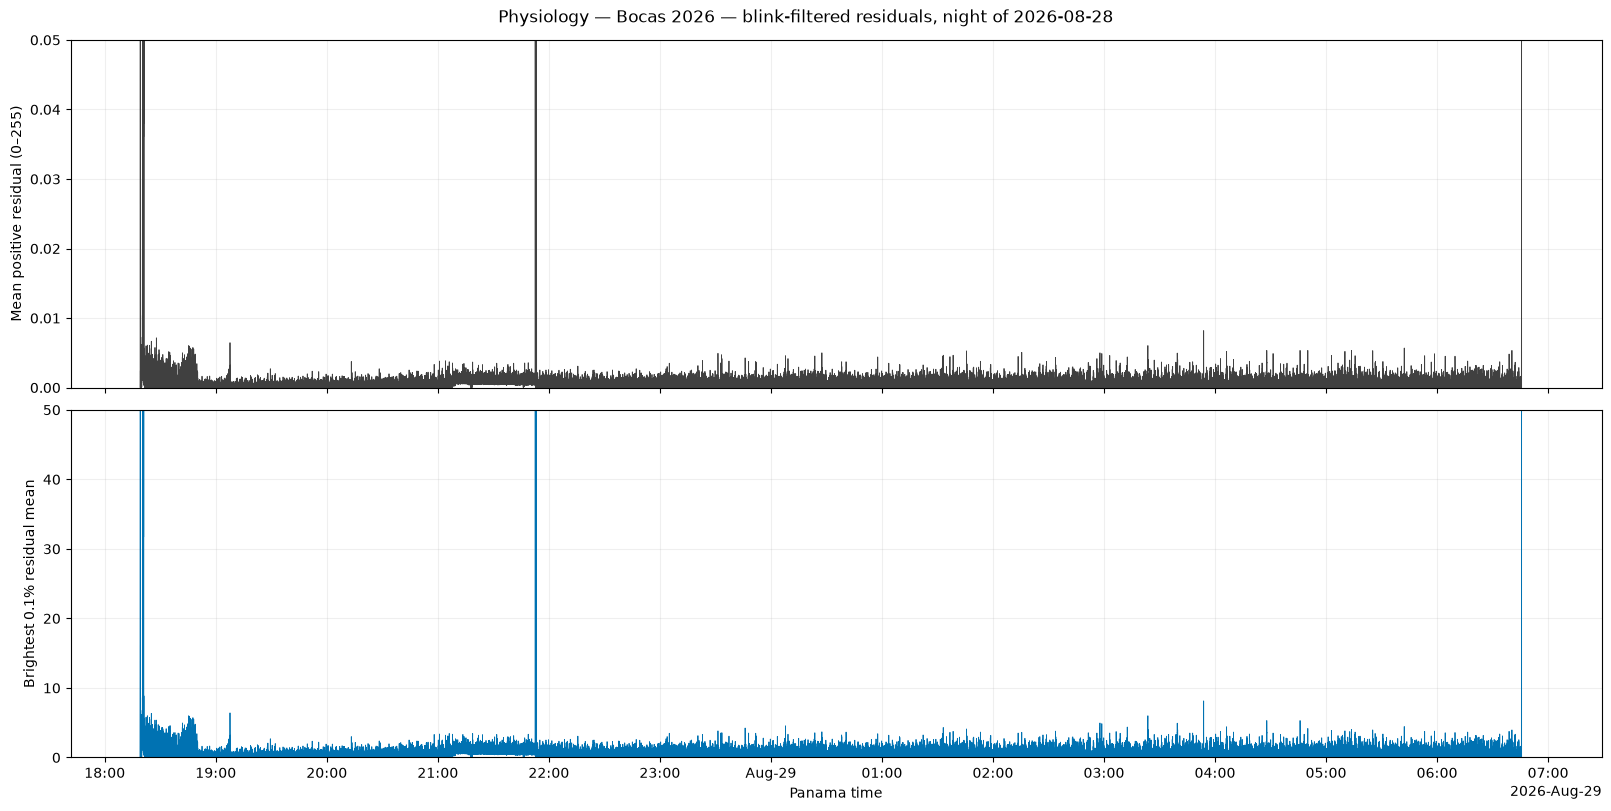

Night 2026-08-29: 134,622 measurements from 375 videos


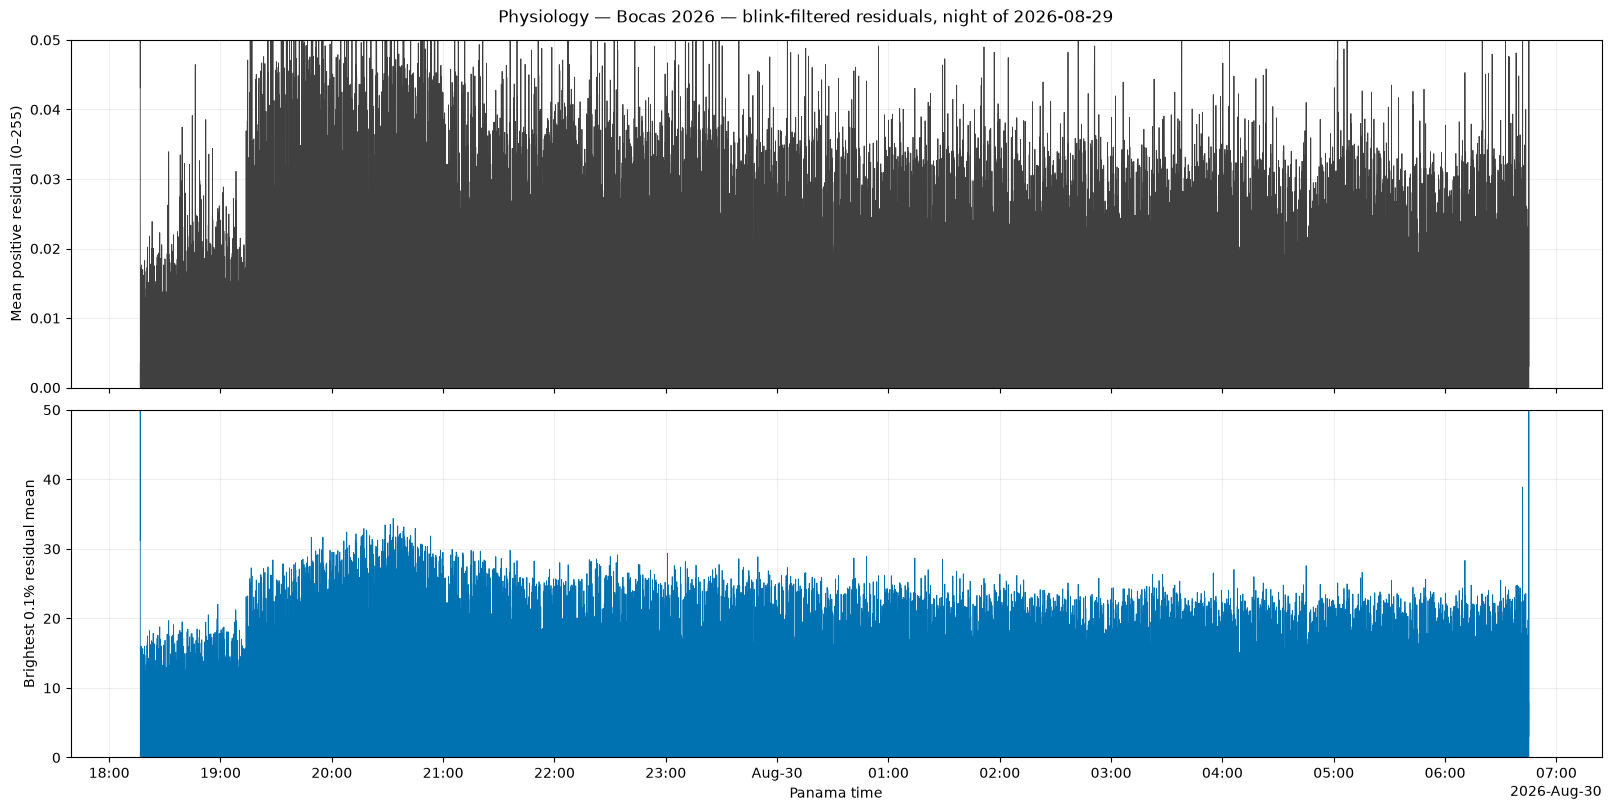

Night 2026-08-30: 114,159 measurements from 318 videos


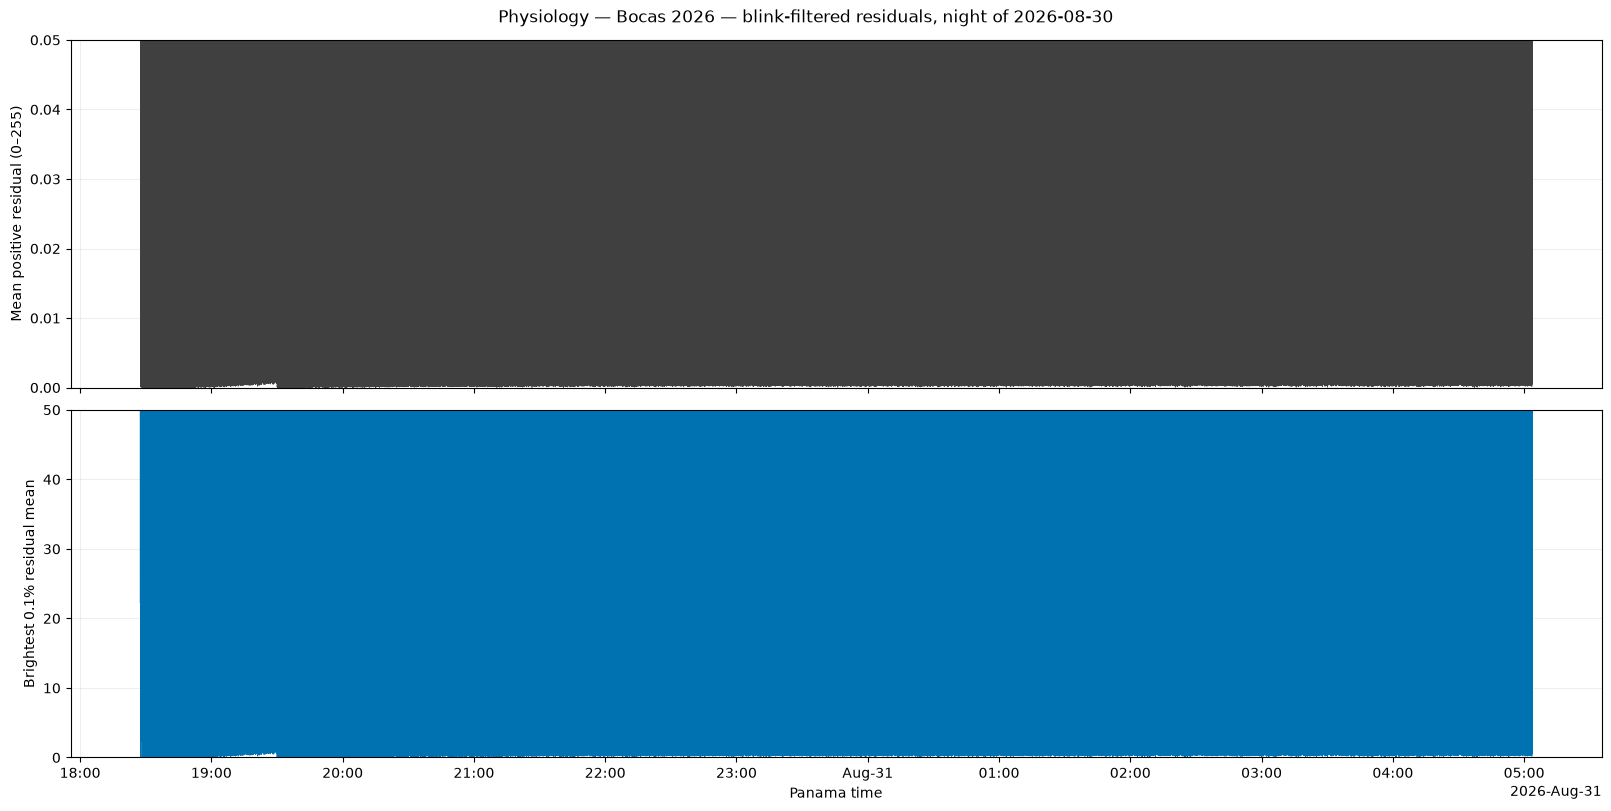

No completed results for night 2026-08-31; skipping plot.
No completed results for night 2026-09-01; skipping plot.


In [29]:
plot_results = {}
for night_date, run in night_runs.items():
    result_files = sorted(run["results_dir"].glob("*_brightness.csv"))
    if not result_files:
        print(f"No completed results for night {night_date}; skipping plot.")
        continue
    results = pd.concat((pd.read_csv(path) for path in result_files), ignore_index=True)
    results["time_panama"] = (
        pd.to_datetime(results["time_utc"], format="mixed", utc=True).dt.tz_convert(TIMEZONE)
    )
    results["night_date"] = results["time_panama"].map(night_label)
    wrong_night = results["night_date"] != night_date
    if wrong_night.any():
        raise RuntimeError(f"{wrong_night.sum():,} measurements were assigned outside night {night_date}.")
    results = results.sort_values("time_panama").reset_index(drop=True)
    plot_results[night_date] = results
    print(f"Night {night_date}: {len(results):,} measurements from {len(result_files)} videos")

    fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True, constrained_layout=True)
    axes[0].plot(results["time_panama"], results["mean_brightness"], lw=0.6, color="0.25")
    axes[1].plot(results["time_panama"], results["top_fraction_mean"], lw=0.6, color="#0072B2")
    axes[0].set_ylabel("Mean positive residual (0–255)")
    axes[1].set_ylabel("Brightest 0.1% residual mean")
    axes[1].set_xlabel("Panama time")
    if MEAN_Y_AXIS_MAX is not None:
        axes[0].set_ylim(0, MEAN_Y_AXIS_MAX)
    if BRIGHT_Y_AXIS_MAX is not None:
        axes[1].set_ylim(0, BRIGHT_Y_AXIS_MAX)
    for axis in axes:
        axis.grid(alpha=0.2)
    locator = mdates.AutoDateLocator(minticks=6, maxticks=16)
    axes[1].xaxis.set_major_locator(locator)
    axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator, tz=local_zone))
    fig.suptitle(f"{DATASET['label']} — blink-filtered residuals, night of {night_date}")
    plt.show()